# 🌳 Decision Tree Classifier from Scratch

**Goal:** Build a tree that recursively partitions the feature space using axis-aligned splits, classifying each region by its majority label.

---

## 1. Algorithm Intuition

A Decision Tree answers questions one at a time:

> *"Is feature $j$ above threshold $t$?"*

It greedily chooses the **best question** at each node — the one that most reduces **impurity** in the resulting child nodes.

### Gini Impurity
$$\text{Gini}(S) = 1 - \sum_{c} p_c^2$$

where $p_c$ is the fraction of examples in set $S$ with label $c$.

- Gini = 0 → perfectly pure node (all same class).
- Gini = 0.5 → maximally impure (50/50 split for 2 classes).

### Information Gain
$$\text{IG}(S, j, t) = \text{Gini}(S) - \left(\frac{|S_L|}{|S|} \text{Gini}(S_L) + \frac{|S_R|}{|S|} \text{Gini}(S_R)\right)$$

We choose the split $(j, t)$ that **maximises** information gain.

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $S$ | current node's dataset |
| $S_L, S_R$ | left / right child datasets after split |
| $p_c$ | fraction of class $c$ in a node |
| `max_depth` | maximum tree depth (stopping criterion) |
| `min_samples_split` | minimum samples required to split a node |


## 2. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

np.random.seed(11)
plt.style.use('seaborn-v0_8-whitegrid')

## 3. Synthetic Data

In [2]:
def make_blobs(n_per_class, centers, std=0.9, seed=11):
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []
    for label, center in enumerate(centers):
        pts = rng.normal(loc=center, scale=std, size=(n_per_class, 2))
        X_list.append(pts)
        y_list.append(np.full(n_per_class, label))
    X = np.vstack(X_list)
    y = np.hstack(y_list)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

centers = [(-2, -2), (2, -2), (0, 2)]
X_all, y_all = make_blobs(n_per_class=100, centers=centers)
print(f"X: {X_all.shape}, y: {y_all.shape}")

X: (300, 2), y: (300,)


## 4. Train / Test Split

In [3]:
def train_test_split(X, y, test_ratio=0.2, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    s = int(len(y) * (1 - test_ratio))
    return X[idx[:s]], X[idx[s:]], y[idx[:s]], y[idx[s:]]

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (240, 2), Test: (60, 2)


## 5. Gini Impurity and Information Gain

In [4]:
def gini_impurity(y):
    """
    Gini(S) = 1 - sum(p_c^2)

    Parameters
    ----------
    y : ndarray (m,) — integer class labels

    Returns
    -------
    float in [0, 1-1/K] where K is number of classes
    """
    m = len(y)
    if m == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probs = counts / m
    return 1.0 - np.sum(probs ** 2)

In [5]:
def information_gain(y_parent, y_left, y_right):
    """
    IG = Gini(parent) - (|left|/|parent|)*Gini(left) - (|right|/|parent|)*Gini(right)
    """
    m  = len(y_parent)
    ml = len(y_left)
    mr = len(y_right)
    if ml == 0 or mr == 0:
        return 0.0
    weighted_gini = (ml / m) * gini_impurity(y_left) + \
                    (mr / m) * gini_impurity(y_right)
    return gini_impurity(y_parent) - weighted_gini

## 6. Best Split Search

In [6]:
def best_split(X, y):
    """
    Find the feature index and threshold that maximise information gain.

    For each feature j:
      - Try every midpoint between adjacent sorted unique values as a threshold t.
      - Compute IG for the resulting split.

    Returns
    -------
    best_feature   : int or None
    best_threshold : float or None
    best_ig        : float
    """
    best_feature   = None
    best_threshold = None
    best_ig        = -1.0

    n_features = X.shape[1]

    for j in range(n_features):
        values = np.sort(np.unique(X[:, j]))
        # Candidate thresholds: midpoints between adjacent unique values
        thresholds = (values[:-1] + values[1:]) / 2.0

        for t in thresholds:
            left_mask  = X[:, j] <= t
            right_mask = ~left_mask

            y_left  = y[left_mask]
            y_right = y[right_mask]

            ig = information_gain(y, y_left, y_right)
            if ig > best_ig:
                best_ig        = ig
                best_feature   = j
                best_threshold = t

    return best_feature, best_threshold, best_ig

## 7. Tree Node Structure

In [7]:
class TreeNode:
    """
    Minimal node class for the decision tree.

    Leaf nodes store a class prediction.
    Internal nodes store a split (feature_idx, threshold) and child pointers.
    """
    def __init__(self, feature=None, threshold=None,
                 left=None, right=None, prediction=None):
        self.feature    = feature      # feature index to split on
        self.threshold  = threshold    # split value
        self.left       = left         # left child TreeNode
        self.right      = right        # right child TreeNode
        self.prediction = prediction   # class label (only for leaf nodes)

## 8. Recursive Tree Building

In [8]:
def build_tree(X, y, depth=0, max_depth=5, min_samples_split=2):
    """
    Recursively build a decision tree.

    Stopping conditions (return a leaf):
      1. All labels in y are the same.
      2. depth >= max_depth.
      3. len(y) < min_samples_split.
    """
    n_samples = len(y)
    n_classes = len(np.unique(y))

    # --- Stopping conditions ---
    if n_classes == 1 or depth >= max_depth or n_samples < min_samples_split:
        # Leaf: predict the most common class
        leaf_prediction = Counter(y.astype(int)).most_common(1)[0][0]
        return TreeNode(prediction=leaf_prediction)

    # --- Find the best split ---
    feat, thresh, ig = best_split(X, y)

    if feat is None or ig == 0:
        leaf_prediction = Counter(y.astype(int)).most_common(1)[0][0]
        return TreeNode(prediction=leaf_prediction)

    # --- Split data ---
    left_mask  = X[:, feat] <= thresh
    right_mask = ~left_mask

    # --- Recursively build children ---
    left_child  = build_tree(X[left_mask],  y[left_mask],
                             depth + 1, max_depth, min_samples_split)
    right_child = build_tree(X[right_mask], y[right_mask],
                             depth + 1, max_depth, min_samples_split)

    return TreeNode(feature=feat, threshold=thresh,
                    left=left_child, right=right_child)

## 9. Prediction

In [9]:
def predict_one(node, x):
    """Traverse the tree for a single sample x."""
    if node.prediction is not None:   # leaf
        return node.prediction
    if x[node.feature] <= node.threshold:
        return predict_one(node.left,  x)
    else:
        return predict_one(node.right, x)

def predict_tree(node, X):
    """Predict class labels for all rows in X."""
    return np.array([predict_one(node, x) for x in X])

## 10. Train the Tree

In [10]:
max_depth = 4
tree = build_tree(X_train, y_train.astype(int), max_depth=max_depth, min_samples_split=5)
print("Tree built successfully.")

Tree built successfully.


## 11. Decision Boundary Visualisation

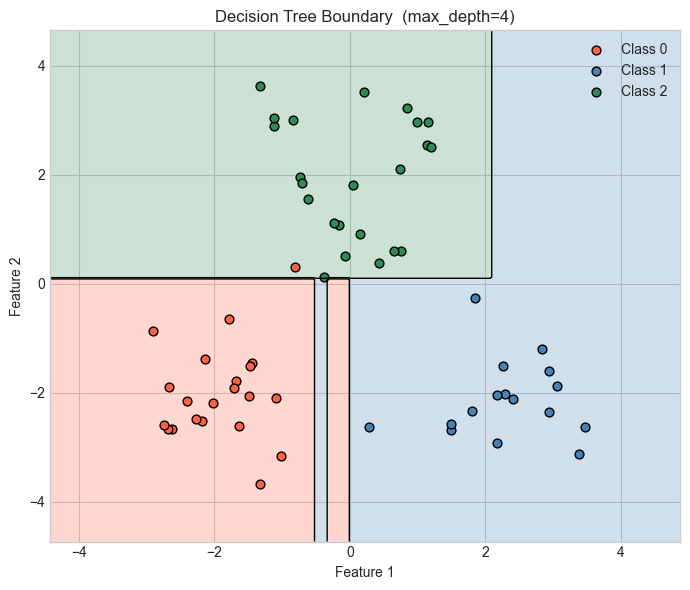

In [11]:
palette = ['tomato', 'steelblue', 'seagreen']

x1_min, x1_max = X_all[:, 0].min() - 0.5, X_all[:, 0].max() + 0.5
x2_min, x2_max = X_all[:, 1].min() - 0.5, X_all[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                     np.linspace(x2_min, x2_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
grid_preds = predict_tree(tree, grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(xx, yy, grid_preds,
            levels=[-0.5, 0.5, 1.5, 2.5],
            colors=palette, alpha=0.25)
ax.contour(xx, yy, grid_preds, levels=[0.5, 1.5], colors='black', linewidths=1)
for cls in range(3):
    mask = y_test.astype(int) == cls
    ax.scatter(X_test[mask, 0], X_test[mask, 1],
               color=palette[cls], edgecolors='k', s=40, label=f'Class {cls}')
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_title(f'Decision Tree Boundary  (max_depth={max_depth})')
ax.legend()
plt.tight_layout()
plt.show()

## 12. Evaluation Metrics

In [12]:
def accuracy(y_true, y_pred):
    return np.mean(y_true.astype(int) == y_pred.astype(int))

y_pred_train = predict_tree(tree, X_train)
y_pred_test  = predict_tree(tree, X_test)

print(f"Train Accuracy: {accuracy(y_train, y_pred_train):.4f}")
print(f"Test  Accuracy: {accuracy(y_test,  y_pred_test):.4f}")

Train Accuracy: 0.9958
Test  Accuracy: 0.9833


## 13. Effect of max_depth — Bias–Variance Tradeoff

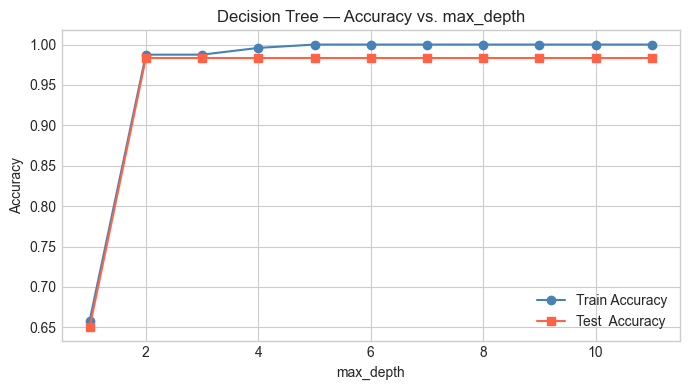

In [13]:
depths       = list(range(1, 12))
train_accs   = []
test_accs    = []

for d in depths:
    t = build_tree(X_train, y_train.astype(int), max_depth=d, min_samples_split=2)
    train_accs.append(accuracy(y_train, predict_tree(t, X_train)))
    test_accs.append(accuracy(y_test,  predict_tree(t, X_test)))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_accs, marker='o', label='Train Accuracy', color='steelblue')
plt.plot(depths, test_accs,  marker='s', label='Test  Accuracy', color='tomato')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree — Accuracy vs. max_depth')
plt.legend()
plt.tight_layout()
plt.show()

## 14. Observations and Limitations

### What we observed
- Axis-aligned (step-like) decision boundaries — visible as horizontal/vertical cuts.
- `max_depth=1` severely underfits; large `max_depth` eventually overfits (train accuracy approaches 100% while test plateaus or drops).
- The bias-variance tradeoff is directly controllable via `max_depth`.

### Limitations
| Limitation | Description |
|------------|-------------|
| **High variance** | Small data changes can produce very different trees. |
| **Axis-aligned splits** | Cannot model diagonal decision boundaries without many levels. |
| **Greedy splitting** | Locally optimal splits may not be globally optimal. |
| **Requires pruning** | Deep trees overfit; `max_depth` must be tuned. |
| **Slow best_split search** | Our implementation is $O(m \cdot n \cdot \text{unique values})$ per node — fine for small datasets. |
